<a href="https://colab.research.google.com/github/faat-prasojo/244107020142_mobile_course/blob/main/Pertemuan%2006/Regresi/Tugas_Praktikum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# 1. IMPORT LIBRARI DAN LOAD DATASET
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Load dataset (pastikan file insurance.csv sudah diunggah di environment Colab)
df = pd.read_csv('insurance.csv')

print("--- Preview Data ---")
print(df.head())
print("\n--- Informasi Dataset ---")
print(df.info())


--- Preview Data ---
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520

--- Informasi Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
None


/tmp/ipykernel_700/2109803942.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='smoker', y='charges', ax=axes[2], palette='Set2')


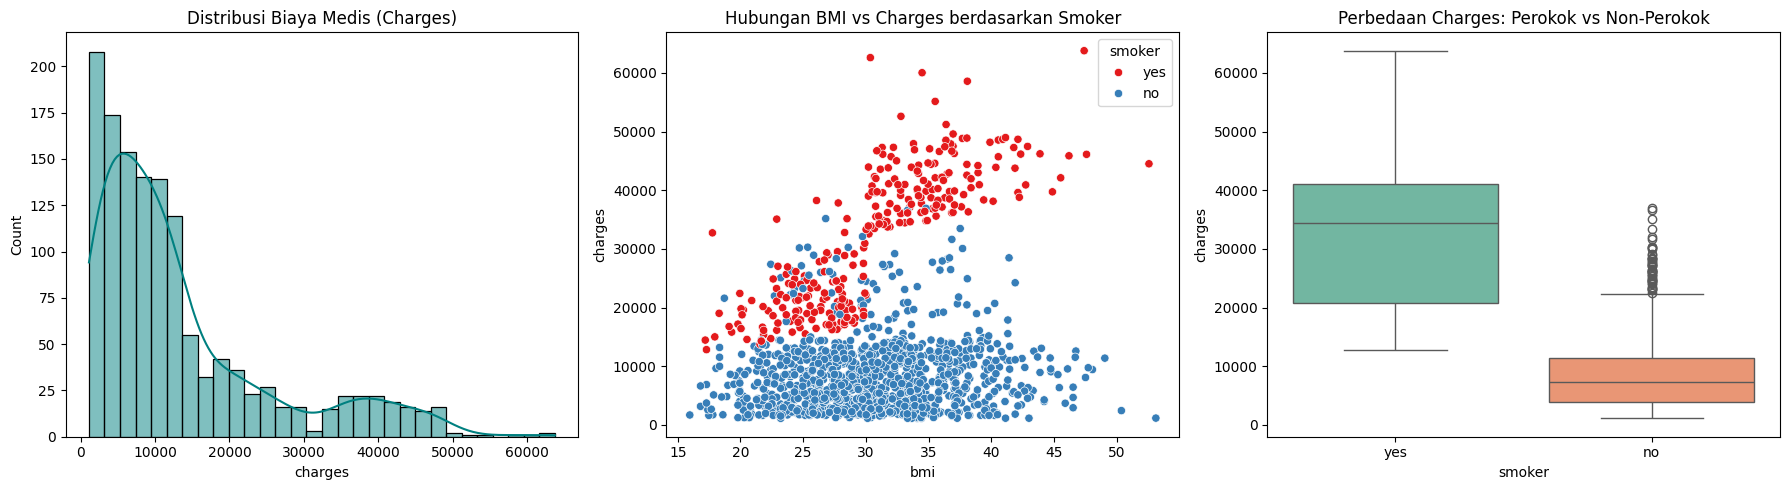

In [3]:
# 2. DESKRIPSI DATASET DAN VISUALISASI
# Visualisasi Distribusi Target dan Fitur Utama
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df['charges'], kde=True, ax=axes[0], color='teal')
axes[0].set_title('Distribusi Biaya Medis (Charges)')

sns.scatterplot(data=df, x='bmi', y='charges', hue='smoker', ax=axes[1], palette='Set1')
axes[1].set_title('Hubungan BMI vs Charges berdasarkan Smoker')

sns.boxplot(data=df, x='smoker', y='charges', ax=axes[2], palette='Set2')
axes[2].set_title('Perbedaan Charges: Perokok vs Non-Perokok')

plt.tight_layout()
plt.show()

In [4]:
# 3. IDENTIFIKASI VARIABEL & ENCODING
# Mengubah variabel kategorikal menjadi numerik menggunakan One-Hot Encoding
df_encoded = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], drop_first=True)

# Variabel Bebas (Fitur/X) dan Variabel Target (y)
X = df_encoded.drop(columns=['charges'])
y = df_encoded['charges']

In [5]:
# 4. PEMBAGIAN DATASET (TRAIN-TEST SPLIT)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [6]:
# 5. FEATURE SCALING
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [7]:
# 6. PEMBUATAN DAN PELATIHAN MODEL
model = LinearRegression()
model.fit(X_train_scaled, y_train)

# Prediksi pada Data Uji
y_pred = model.predict(X_test_scaled)


--- HASIL EVALUASI MODEL ---
R-squared (R2)          : 0.7836
Mean Absolute Error (MAE): 4181.19
Mean Squared Error (MSE) : 33596915.85
Root Mean Sq Error (RMSE): 5796.28


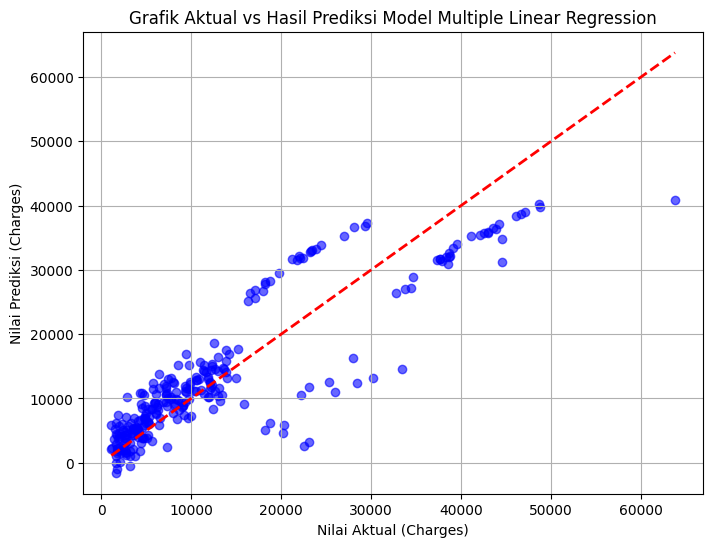

In [8]:
# 7. EVALUASI MODEL
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("\n--- HASIL EVALUASI MODEL ---")
print(f"R-squared (R2)          : {r2:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE) : {mse:.2f}")
print(f"Root Mean Sq Error (RMSE): {rmse:.2f}")

# Visualisasi Aktual vs Prediksi
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Nilai Aktual (Charges)')
plt.ylabel('Nilai Prediksi (Charges)')
plt.title('Grafik Aktual vs Hasil Prediksi Model Multiple Linear Regression')
plt.grid(True)
plt.show()

Analisis Hasil Praktikum
- Performa Model ($R^2 = 0.7836$): Model Multiple Linear Regression mampu menjelaskan sekitar 78.36% variasi dari tagihan medis personal berdasarkan fitur-fitur yang ada. Sisanya (sekitar 21.64%) dipengaruhi oleh faktor lain di luar dataset.
- Tingkat Kesalahan (MAE & RMSE): Nilai MAE sebesar 4.181,19 menunjukkan bahwa secara rata-rata, prediksi tagihan medis meleset sekitar $4.181 dari nilai aktualnya.
- Pengaruh Variabel Terbesar: Berdasarkan eksplorasi visual, variabel smoker (status merokok) dan bmi memiliki pengaruh paling signifikan terhadap kenaikan biaya medis. Perokok dengan BMI tinggi cenderung mendapatkan tagihan medis jauh lebih besar dibandingkan non-perokok.